# Predicción Inicial con Machine Learning

Este notebook construye un primer modelo predictivo para estimar la calificación de una actividad evaluable a partir del comportamiento histórico previo del estudiante.

## Objetivo

Preparar un dataset histórico, construir un baseline y entrenar un modelo de regresión lineal para estimar `score` sin utilizar información futura.

## Pregunta predictiva

¿Es posible estimar la calificación de la próxima actividad evaluable de un estudiante utilizando únicamente información académica disponible antes de esa actividad?

## Tipo de problema

Se utilizará un enfoque de regresión debido a que la variable objetivo `score` es numérica.

## Consideración metodológica

Las variables predictoras serán construidas únicamente con información histórica previa para evitar fuga de información.

In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [57]:
import sklearn

print(sklearn.__version__)

1.9.1


## Dependencias del modelo

Se utiliza `scikit-learn` para construir el baseline, entrenar la regresión lineal y calcular las métricas de evaluación.

In [58]:
## Reproducibilidad

Se define una semilla fija para mantener resultados reproducibles en las operaciones que utilicen aleatoriedad.

SyntaxError: invalid syntax (1117419034.py, line 3)

In [ ]:
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## Fuente de datos

Se utiliza el dataset limpio generado durante la etapa de preparación e ingeniería de características.

In [ ]:
from pathlib import Path

PROJECT_ROOT = Path("..")

DATA_FILE = (
    PROJECT_ROOT
    / "datos"
    / "procesados"
    / "edtech_dataset_limpio.csv"
)

print(DATA_FILE)

..\datos\procesados\edtech_dataset_limpio.csv


## Carga del dataset

Se carga la versión limpia del dataset para construir las variables históricas requeridas por el modelo.

In [ ]:
df = pd.read_csv(DATA_FILE)

print("Filas:", len(df))
print("Columnas:", len(df.columns))

display(df.head())

Filas: 200000
Columnas: 36


,interaction_id,student_id,course_id,timestamp,activity_type,duration_seconds,completion_rate,score,attempts,device_used,...,course_format,has_assignments,has_quizzes,has_discussion_forum,certificate_offered,interaction_year,interaction_month,interaction_week,duration_minutes,average_student_score
0,interaction_000000,student_02020,course_078,2024-10-24 22:02:09,Note Taking,392,1.0,NaN,1,Tablet,...,Video,1,1,0,1,2024,10,43,6.53,0.7837
1,interaction_000001,student_07410,course_067,2024-11-15 19:41:09,Assignment Submit,1683,1.0,0.9,2,Mobile,...,Mixed,1,1,1,1,2024,11,46,28.05,0.8064
2,interaction_000002,student_03086,course_134,2024-06-29 21:33:09,Resource Download,1215,0.0,NaN,1,Desktop,...,Text-based,1,1,0,0,2024,6,26,20.25,0.8422
3,interaction_000003,student_05092,course_112,2024-11-18 03:24:09,Note Taking,274,0.0,NaN,1,Desktop,...,Mixed,0,1,0,1,2024,11,47,4.57,0.7217
4,interaction_000004,student_03626,course_011,2024-06-30 03:13:09,Note Taking,821,1.0,NaN,1,Mobile,...,Video,1,1,1,1,2024,6,26,13.68,0.8467


## Revisión inicial

Se verifica la estructura, los tipos de datos, valores nulos y rango temporal antes de preparar el modelo.

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 36 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   interaction_id           200000 non-null  str    
 1   student_id               200000 non-null  str    
 2   course_id                200000 non-null  str    
 3   timestamp                200000 non-null  str    
 4   activity_type            200000 non-null  str    
 5   duration_seconds         200000 non-null  int64  
 6   completion_rate          200000 non-null  float64
 7   score                    66581 non-null   float64
 8   attempts                 200000 non-null  int64  
 9   device_used              200000 non-null  str    
 10  help_sought              200000 non-null  bool   
 11  peer_interaction         200000 non-null  bool   
 12  age                      200000 non-null  int64  
 13  education_level          200000 non-null  str    
 14  study_field    

In [ ]:
df.isnull().sum().sort_values(ascending=False).head(10)

score                    133419
average_student_score        38
interaction_id                0
student_id                    0
timestamp                     0
course_id                     0
duration_seconds              0
activity_type                 0
attempts                      0
device_used                   0
dtype: int64

In [ ]:
df["timestamp"] = pd.to_datetime(
    df["timestamp"],
    errors="coerce"
)

print("Fecha mínima:", df["timestamp"].min())
print("Fecha máxima:", df["timestamp"].max())

Fecha mínima: 2024-06-12 13:55:11
Fecha máxima: 2025-06-12 13:50:19


## Variable objetivo

La variable objetivo será `score`.

Los valores nulos se mantienen fuera del modelado porque corresponden principalmente a actividades que no requieren calificación.

In [ ]:
print(df["score"].describe())
print()
print("Score nulo:", df["score"].isnull().sum())
print("Score disponible:", df["score"].notnull().sum())

count    66581.000000
mean         0.799858
std          0.115322
min          0.600000
25%          0.700000
50%          0.800000
75%          0.900000
max          1.000000
Name: score, dtype: float64

Score nulo: 133419
Score disponible: 66581


## Actividades evaluables

El modelo utilizará únicamente interacciones con `score` disponible, correspondientes a actividades evaluables.

In [ ]:
df_evaluable = (
    df[df["score"].notnull()]
    .copy()
)

print("Interacciones evaluables:", len(df_evaluable))

display(
    df_evaluable["activity_type"]
    .value_counts()
)

Interacciones evaluables: 66581


activity_type
Quiz Attempt         33411
Assignment Submit    33170
Name: count, dtype: int64

## Orden temporal

Los registros se ordenan por estudiante y fecha para construir variables históricas utilizando únicamente información disponible antes de cada actividad evaluable.

In [ ]:
df_modelo = (
    df_evaluable
    .sort_values(["student_id", "timestamp"])
    .copy()
)

display(
    df_modelo[
        ["student_id", "timestamp", "activity_type", "score"]
    ].head(10)
)

,student_id,timestamp,activity_type,score
194741,student_00000,2024-06-19 16:29:19,Assignment Submit,0.62
77404,student_00000,2024-11-17 18:31:13,Assignment Submit,0.89
183699,student_00000,2024-12-08 21:18:19,Quiz Attempt,0.99
26559,student_00000,2025-02-14 18:09:10,Assignment Submit,0.84
97053,student_00000,2025-03-23 23:33:14,Quiz Attempt,0.74
16490,student_00000,2025-04-20 04:09:09,Quiz Attempt,1.00
89662,student_00000,2025-05-11 04:58:14,Quiz Attempt,0.92
36944,student_00000,2025-05-25 15:07:11,Assignment Submit,0.70
37124,student_00001,2024-06-17 09:55:11,Quiz Attempt,0.82
130989,student_00001,2024-08-30 04:45:16,Assignment Submit,0.61


## Calificación previa

Se crea `previous_score` con la calificación evaluable inmediatamente anterior de cada estudiante.

In [ ]:
df_modelo["previous_score"] = (
    df_modelo
    .groupby("student_id")["score"]
    .shift(1)
)

## Promedio histórico de calificaciones

Se calcula el promedio de las calificaciones anteriores del estudiante sin incluir la actividad que se intenta predecir.

In [ ]:
df_modelo["average_previous_score"] = (
    df_modelo
    .groupby("student_id")["score"]
    .transform(
        lambda s: s.shift(1).expanding().mean()
    )
)

## Historial de finalización

Se genera el promedio histórico de `completion_rate` utilizando únicamente actividades evaluables anteriores.

In [ ]:
df_modelo["average_previous_completion"] = (
    df_modelo
    .groupby("student_id")["completion_rate"]
    .transform(
        lambda s: s.shift(1).expanding().mean()
    )
)

## Duración histórica

Se calcula la duración promedio de las actividades evaluables realizadas previamente por cada estudiante.

In [ ]:
df_modelo["average_previous_duration"] = (
    df_modelo
    .groupby("student_id")["duration_minutes"]
    .transform(
        lambda s: s.shift(1).expanding().mean()
    )
)

## Historial de actividades

Se calcula la cantidad de actividades evaluables realizadas antes de cada observación.

In [ ]:
df_modelo["previous_evaluated_count"] = (
    df_modelo
    .groupby("student_id")
    .cumcount()
)

## Intentos históricos

Se calcula el promedio de intentos registrados en actividades evaluables anteriores.

In [ ]:
df_modelo["average_previous_attempts"] = (
    df_modelo
    .groupby("student_id")["attempts"]
    .transform(
        lambda s: s.shift(1).expanding().mean()
    )
)

## Validación de variables históricas

Se revisan las nuevas características para confirmar que las primeras observaciones de cada estudiante no contienen historial previo.

In [ ]:
columnas_revision = [
    "student_id",
    "timestamp",
    "score",
    "previous_score",
    "average_previous_score",
    "average_previous_completion",
    "average_previous_duration",
    "average_previous_attempts",
    "previous_evaluated_count"
]

display(
    df_modelo[columnas_revision].head(20)
)

,student_id,timestamp,score,previous_score,average_previous_score,average_previous_completion,average_previous_duration,average_previous_attempts,previous_evaluated_count
194741,student_00000,2024-06-19 16:29:19,0.62,NaN,NaN,NaN,NaN,NaN,0
77404,student_00000,2024-11-17 18:31:13,0.89,0.62,0.620000,1.000000,0.020000,3.000000,1
183699,student_00000,2024-12-08 21:18:19,0.99,0.89,0.755000,1.000000,4.910000,2.000000,2
26559,student_00000,2025-02-14 18:09:10,0.84,0.99,0.833333,1.000000,8.890000,1.666667,3
97053,student_00000,2025-03-23 23:33:14,0.74,0.84,0.835000,1.000000,7.375000,2.000000,4
16490,student_00000,2025-04-20 04:09:09,1.00,0.74,0.816000,1.000000,9.684000,1.800000,5
89662,student_00000,2025-05-11 04:58:14,0.92,1.00,0.846667,1.000000,12.036667,2.000000,6
36944,student_00000,2025-05-25 15:07:11,0.70,0.92,0.857143,1.000000,13.552857,2.000000,7
37124,student_00001,2024-06-17 09:55:11,0.82,NaN,NaN,NaN,NaN,NaN,0
130989,student_00001,2024-08-30 04:45:16,0.61,0.82,0.820000,1.000000,23.430000,2.000000,1


## Dataset para modelado

Se eliminan únicamente las observaciones que no cuentan con historial suficiente para construir las variables predictoras.

In [ ]:
features = [
    "previous_score",
    "average_previous_score",
    "average_previous_completion",
    "average_previous_duration",
    "average_previous_attempts",
    "previous_evaluated_count",
    "previous_online_courses"
]

In [ ]:
df_ml = df_modelo.dropna(
    subset=features + ["score"]
).copy()

print("Actividades evaluables originales:", len(df_modelo))
print("Registros disponibles para ML:", len(df_ml))

Actividades evaluables originales: 66581
Registros disponibles para ML: 58583


In [ ]:
display(
    df_ml[
        features + ["score"]
    ].head()
)

,previous_score,average_previous_score,average_previous_completion,average_previous_duration,average_previous_attempts,previous_evaluated_count,previous_online_courses,score
77404,0.62,0.620000,1.0,0.020,3.000000,1,1,0.89
183699,0.89,0.755000,1.0,4.910,2.000000,2,1,0.99
26559,0.99,0.833333,1.0,8.890,1.666667,3,1,0.84
97053,0.84,0.835000,1.0,7.375,2.000000,4,1,0.74
16490,0.74,0.816000,1.0,9.684,1.800000,5,1,1.00


## Variables del modelo

Se definen las variables predictoras `X` y la variable objetivo `y` utilizando únicamente información histórica disponible antes de cada actividad.

In [ ]:
X = df_ml[features].copy()
y = df_ml["score"].copy()

print("X:", X.shape)
print("y:", y.shape)

display(X.head())

X: (58583, 7)
y: (58583,)


,previous_score,average_previous_score,average_previous_completion,average_previous_duration,average_previous_attempts,previous_evaluated_count,previous_online_courses
77404,0.62,0.620000,1.0,0.020,3.000000,1,1
183699,0.89,0.755000,1.0,4.910,2.000000,2,1
26559,0.99,0.833333,1.0,8.890,1.666667,3,1
97053,0.84,0.835000,1.0,7.375,2.000000,4,1
16490,0.74,0.816000,1.0,9.684,1.800000,5,1


## Orden cronológico para modelado

El dataset se ordena por fecha para asegurar que el entrenamiento utilice observaciones anteriores a las utilizadas en prueba.

In [ ]:
df_ml = (
    df_ml
    .sort_values("timestamp")
    .reset_index(drop=True)
)

X = df_ml[features]
y = df_ml["score"]

print("Fecha inicial:", df_ml["timestamp"].min())
print("Fecha final:", df_ml["timestamp"].max())

Fecha inicial: 2024-06-13 03:22:15
Fecha final: 2025-06-12 13:45:13


## División entrenamiento y prueba

Se utiliza una partición cronológica 80/20 para simular la predicción de observaciones futuras y evitar fuga de información.

In [ ]:
corte = int(len(df_ml) * 0.80)

X_train = X.iloc[:corte]
X_test = X.iloc[corte:]

y_train = y.iloc[:corte]
y_test = y.iloc[corte:]

fecha_train = df_ml["timestamp"].iloc[:corte]
fecha_test = df_ml["timestamp"].iloc[corte:]

In [ ]:
print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)

print()
print("Última fecha entrenamiento:", fecha_train.max())
print("Primera fecha prueba:", fecha_test.min())

Entrenamiento: (46866, 7)
Prueba: (11717, 7)

Última fecha entrenamiento: 2025-04-08 12:47:19
Primera fecha prueba: 2025-04-08 12:58:16


## Validación temporal

Se verifica que el conjunto de prueba corresponda al periodo más reciente del dataset.

In [ ]:
print(
    "Periodo entrenamiento:",
    fecha_train.min(),
    "→",
    fecha_train.max()
)

print(
    "Periodo prueba:",
    fecha_test.min(),
    "→",
    fecha_test.max()
)

Periodo entrenamiento: 2024-06-13 03:22:15 → 2025-04-08 12:47:19
Periodo prueba: 2025-04-08 12:58:16 → 2025-06-12 13:45:13


In [ ]:
print(
    "Entrenamiento:",
    round(len(X_train) / len(df_ml) * 100, 2),
    "%"
)

print(
    "Prueba:",
    round(len(X_test) / len(df_ml) * 100, 2),
    "%"
)

Entrenamiento: 80.0 %
Prueba: 20.0 %


## Baseline

Se construye un modelo de referencia que predice siempre la media de las calificaciones observadas en el conjunto de entrenamiento.

In [ ]:
baseline = DummyRegressor(strategy="mean")

baseline.fit(
    X_train,
    y_train
)

pred_baseline = baseline.predict(X_test)

## Evaluación del baseline

Se calculan MAE, RMSE y R² para establecer una referencia mínima de desempeño antes de entrenar el modelo predictivo.

In [ ]:
mae_base = mean_absolute_error(
    y_test,
    pred_baseline
)

rmse_base = mean_squared_error(
    y_test,
    pred_baseline
) ** 0.5

r2_base = r2_score(
    y_test,
    pred_baseline
)

print("Baseline MAE:", round(mae_base, 4))
print("Baseline RMSE:", round(rmse_base, 4))
print("Baseline R²:", round(r2_base, 4))

Baseline MAE: 0.0999
Baseline RMSE: 0.1154
Baseline R²: -0.0


In [ ]:
print(
    "Media de score en entrenamiento:",
    round(y_train.mean(), 4)
)

print(
    "Media de score en prueba:",
    round(y_test.mean(), 4)
)

Media de score en entrenamiento: 0.8
Media de score en prueba: 0.8


## Métricas iniciales

Se registra el desempeño del baseline para utilizarlo posteriormente como punto de comparación con la regresión lineal.

In [ ]:
metricas_baseline = pd.DataFrame({
    "Modelo": ["Baseline media"],
    "MAE": [mae_base],
    "RMSE": [rmse_base],
    "R2": [r2_base]
})

display(metricas_baseline)

,Modelo,MAE,RMSE,R2
0,Baseline media,0.099906,0.115371,-8.866304e-08


## Regresión lineal

Se entrena un modelo de regresión lineal utilizando las variables históricas seleccionadas para estimar `score`.

In [ ]:
modelo = LinearRegression()

modelo.fit(
    X_train,
    y_train
)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](7,)","[ 0.01,-0.01, 0. ,..., 0. ,-0. , 0. ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](7,)","['previous_score','average_previous_score','average_previous_completion', ...,'average_previous_attempts','previous_evaluated_count', 'previous_online_courses']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.7945
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(7)


## Predicciones

El modelo entrenado se utiliza para estimar las calificaciones del conjunto de prueba.

In [ ]:
pred = modelo.predict(X_test)

In [ ]:
comparacion_pred = pd.DataFrame({
    "real": y_test.values,
    "prediccion": pred
})

display(comparacion_pred.head(10))

,real,prediccion
0,0.66,0.798282
1,0.63,0.798592
2,0.61,0.799049
3,0.82,0.797101
4,0.78,0.797891
5,0.62,0.799986
6,0.62,0.799549
7,0.91,0.800035
8,0.94,0.801825
9,0.77,0.800851


## Evaluación del modelo

Se calculan MAE, RMSE y R² para medir el desempeño de la regresión lineal sobre datos no utilizados durante el entrenamiento.

In [ ]:
mae = mean_absolute_error(
    y_test,
    pred
)

rmse = mean_squared_error(
    y_test,
    pred
) ** 0.5

r2 = r2_score(
    y_test,
    pred
)

print("Modelo MAE:", round(mae, 4))
print("Modelo RMSE:", round(rmse, 4))
print("Modelo R²:", round(r2, 4))

Modelo MAE: 0.0999
Modelo RMSE: 0.1154
Modelo R²: -0.0


## Comparación con el baseline

El desempeño de la regresión lineal se compara con la predicción basada únicamente en la media del conjunto de entrenamiento.

In [ ]:
comparacion_metricas = pd.DataFrame({
    "Modelo": [
        "Baseline media",
        "Regresión lineal"
    ],
    "MAE": [
        mae_base,
        mae
    ],
    "RMSE": [
        rmse_base,
        rmse
    ],
    "R2": [
        r2_base,
        r2
    ]
})

display(comparacion_metricas)

,Modelo,MAE,RMSE,R2
0,Baseline media,0.099906,0.115371,-8.866304e-08
1,Regresión lineal,0.099929,0.115373,-2.375714e-05


## Mejora frente al baseline

Se calcula el porcentaje de mejora del MAE para determinar si la regresión lineal aporta valor frente a una predicción simple.

In [ ]:
mejora_mae = (
    (mae_base - mae)
    / mae_base
) * 100

print(
    "Mejora del MAE frente al baseline:",
    round(mejora_mae, 2),
    "%"
)

Mejora del MAE frente al baseline: -0.02 %


## Valores reales y predicciones

Se comparan las calificaciones reales y estimadas durante el periodo de prueba para observar diferencias y patrones de error.

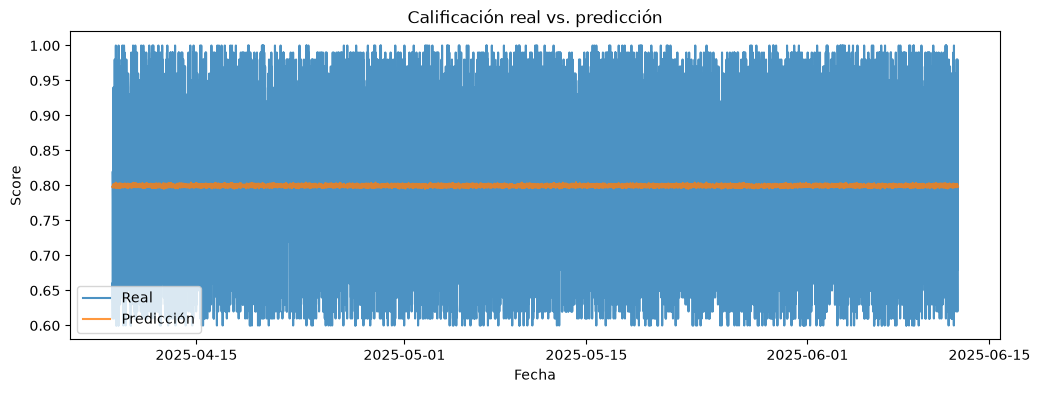

In [ ]:
plt.figure(figsize=(12, 4))

plt.plot(
    fecha_test.values,
    y_test.values,
    label="Real",
    alpha=0.8
)

plt.plot(
    fecha_test.values,
    pred,
    label="Predicción",
    alpha=0.8
)

plt.title(
    "Calificación real vs. predicción"
)

plt.xlabel("Fecha")
plt.ylabel("Score")
plt.legend()

plt.show()

## Comparación real vs. predicho

Se utiliza un gráfico de dispersión para evaluar qué tan cerca se encuentran las predicciones de los valores reales.

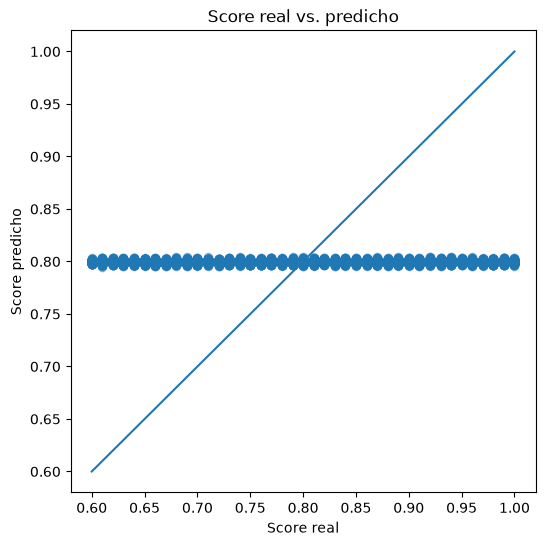

In [ ]:
plt.figure(figsize=(6, 6))

plt.scatter(
    y_test,
    pred,
    alpha=0.4
)

lim_min = min(
    y_test.min(),
    pred.min()
)

lim_max = max(
    y_test.max(),
    pred.max()
)

plt.plot(
    [lim_min, lim_max],
    [lim_min, lim_max]
)

plt.xlabel("Score real")
plt.ylabel("Score predicho")

plt.title(
    "Score real vs. predicho"
)

plt.show()

## Resultados de prueba

Se construye una tabla con los valores reales, predicciones y errores individuales del modelo.

In [ ]:
resultados = pd.DataFrame({
    "timestamp": fecha_test.values,
    "student_id": df_ml["student_id"].iloc[corte:].values,
    "score_real": y_test.values,
    "score_predicho": pred
})

resultados["residuo"] = (
    resultados["score_real"]
    - resultados["score_predicho"]
)

resultados["error_absoluto"] = (
    resultados["residuo"]
    .abs()
)

display(resultados.head())

,timestamp,student_id,score_real,score_predicho,residuo,error_absoluto
0,2025-04-08 12:58:16,student_05801,0.66,0.798282,-0.138282,0.138282
1,2025-04-08 13:08:15,student_03661,0.63,0.798592,-0.168592,0.168592
2,2025-04-08 13:23:15,student_06682,0.61,0.799049,-0.189049,0.189049
3,2025-04-08 13:32:09,student_00325,0.82,0.797101,0.022899,0.022899
4,2025-04-08 13:50:14,student_03840,0.78,0.797891,-0.017891,0.017891


## Análisis de residuos

Los residuos permiten identificar cuánto y en qué dirección se diferencia cada predicción del valor real.

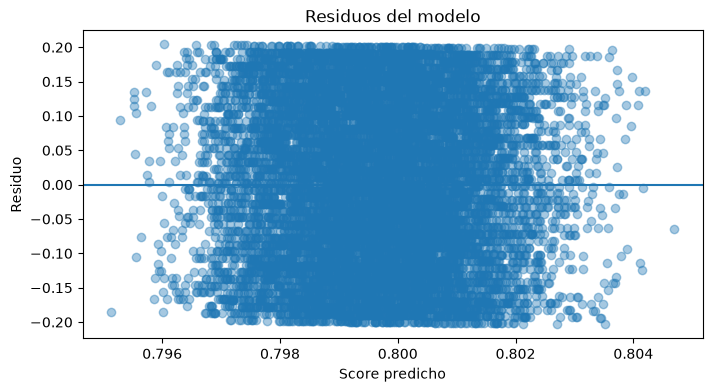

In [ ]:
plt.figure(figsize=(8, 4))

plt.scatter(
    resultados["score_predicho"],
    resultados["residuo"],
    alpha=0.4
)

plt.axhline(
    y=0
)

plt.xlabel("Score predicho")
plt.ylabel("Residuo")

plt.title(
    "Residuos del modelo"
)

plt.show()

## Mayores errores

Se identifican las observaciones donde el modelo presentó las diferencias absolutas más grandes.

In [ ]:
mayores_errores = (
    resultados
    .nlargest(
        10,
        "error_absoluto"
    )
)

display(mayores_errores)

,timestamp,student_id,score_real,score_predicho,residuo,error_absoluto
10746,2025-06-06 23:14:15,student_02152,1.0,0.796024,0.203976,0.203976
9586,2025-05-31 10:50:16,student_00747,0.6,0.803523,-0.203523,0.203523
11567,2025-06-11 16:25:13,student_02489,1.0,0.796580,0.203420,0.203420
5630,2025-05-09 14:39:09,student_04371,1.0,0.796827,0.203173,0.203173
8909,2025-05-27 16:54:14,student_02761,1.0,0.796872,0.203128,0.203128
80,2025-04-09 00:18:15,student_06846,1.0,0.797210,0.202790,0.202790
9250,2025-05-29 14:07:19,student_06347,1.0,0.797265,0.202735,0.202735
2445,2025-04-22 10:34:20,student_05230,0.6,0.802699,-0.202699,0.202699
6736,2025-05-15 18:16:09,student_02152,1.0,0.797340,0.202660,0.202660
9946,2025-06-02 12:58:17,student_02053,1.0,0.797393,0.202607,0.202607


## Interpretación inicial

El desempeño del modelo debe evaluarse comparando sus métricas con el baseline.

Un R² positivo no es suficiente para considerar útil el modelo. También deben revisarse MAE, RMSE, residuos y el contexto académico de las predicciones.

## Interpretación de resultados

La regresión lineal presentó un desempeño prácticamente igual al baseline.

El MAE fue aproximadamente 0.10, equivalente a un error promedio cercano a 10 puntos porcentuales en la escala de `score`.

El R² fue cercano a 0, lo que indica que el modelo no explica una proporción relevante de la variabilidad observada en las calificaciones del conjunto de prueba.

La mejora del MAE frente al baseline fue de aproximadamente -0.02 %, por lo que el modelo no aporta una ventaja predictiva respecto a utilizar únicamente la media histórica.

## Conclusión del modelo inicial

El modelo de regresión lineal no proporciona evidencia suficiente para utilizarse como herramienta predictiva en su configuración actual.

Este resultado no implica que la calificación sea impredecible, sino que las variables seleccionadas y una relación lineal simple no contienen suficiente señal predictiva para superar al baseline.

Se requiere explorar nuevas características, relaciones no lineales o modelos alternativos antes de considerar un uso operativo.

## Coeficientes del modelo

Se revisan los coeficientes de la regresión lineal para identificar la dirección y magnitud de la relación entre cada variable predictora y `score`.

In [ ]:
coeficientes = pd.DataFrame({
    "variable": features,
    "coeficiente": modelo.coef_
})

coeficientes["coef_abs"] = (
    coeficientes["coeficiente"]
    .abs()
)

coeficientes = coeficientes.sort_values(
    "coef_abs",
    ascending=False
)

display(coeficientes)

,variable,coeficiente,coef_abs
0,previous_score,0.009896,0.009896
1,average_previous_score,-0.008365,0.008365
4,average_previous_attempts,0.002202,0.002202
6,previous_online_courses,0.000231,0.000231
2,average_previous_completion,0.000099,0.000099
5,previous_evaluated_count,-0.000088,0.000088
3,average_previous_duration,-0.000080,0.000080


## Interpretación de coeficientes

Los coeficientes permiten observar la relación estimada por el modelo entre cada predictor y la calificación.

Debido al bajo desempeño general de la regresión, estos valores deben interpretarse únicamente como relaciones internas del modelo y no como evidencia de causalidad o importancia predictiva definitiva.

## Distribución de residuos

Se analiza la distribución de los errores para identificar si las predicciones presentan sesgos o patrones sistemáticos.

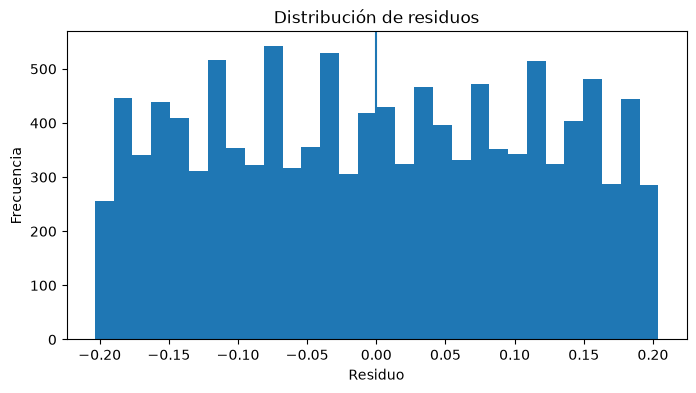

In [ ]:
plt.figure(figsize=(8, 4))

plt.hist(
    resultados["residuo"],
    bins=30
)

plt.axvline(
    x=0
)

plt.xlabel("Residuo")
plt.ylabel("Frecuencia")

plt.title(
    "Distribución de residuos"
)

plt.show()

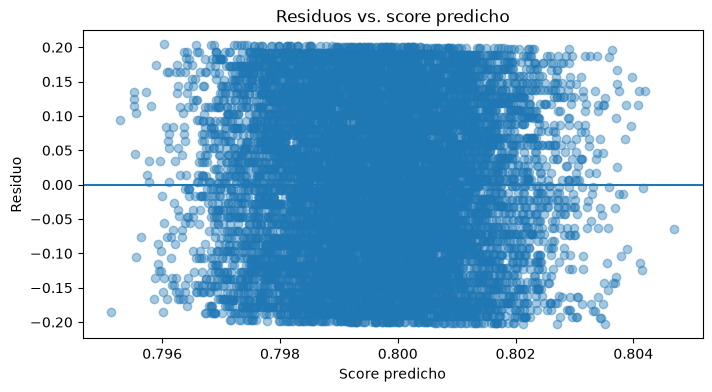

In [ ]:
plt.figure(figsize=(8, 4))

plt.scatter(
    resultados["score_predicho"],
    resultados["residuo"],
    alpha=0.4
)

plt.axhline(y=0)

plt.xlabel("Score predicho")
plt.ylabel("Residuo")

plt.title(
    "Residuos vs. score predicho"
)

plt.show()

## Resumen de errores

Se calculan estadísticas descriptivas de los residuos y del error absoluto para evaluar la magnitud general de los errores.

In [ ]:
display(
    resultados[
        ["residuo", "error_absoluto"]
    ].describe()
)

,residuo,error_absoluto
count,11717.000000,11717.000000
mean,0.000343,0.099929
std,0.115377,0.057666
min,-0.203523,0.000001
25%,-0.099637,0.050002
50%,0.000210,0.100051
75%,0.100450,0.149753
max,0.203976,0.203976


In [ ]:
mayores_errores = (
    resultados
    .nlargest(
        10,
        "error_absoluto"
    )
)

display(mayores_errores)

,timestamp,student_id,score_real,score_predicho,residuo,error_absoluto
10746,2025-06-06 23:14:15,student_02152,1.0,0.796024,0.203976,0.203976
9586,2025-05-31 10:50:16,student_00747,0.6,0.803523,-0.203523,0.203523
11567,2025-06-11 16:25:13,student_02489,1.0,0.796580,0.203420,0.203420
5630,2025-05-09 14:39:09,student_04371,1.0,0.796827,0.203173,0.203173
8909,2025-05-27 16:54:14,student_02761,1.0,0.796872,0.203128,0.203128
80,2025-04-09 00:18:15,student_06846,1.0,0.797210,0.202790,0.202790
9250,2025-05-29 14:07:19,student_06347,1.0,0.797265,0.202735,0.202735
2445,2025-04-22 10:34:20,student_05230,0.6,0.802699,-0.202699,0.202699
6736,2025-05-15 18:16:09,student_02152,1.0,0.797340,0.202660,0.202660
9946,2025-06-02 12:58:17,student_02053,1.0,0.797393,0.202607,0.202607


## Análisis de errores

Los residuos permiten evaluar si el modelo presenta errores sistemáticos o dificultades particulares en determinados rangos de calificación.

Debido a que la regresión lineal obtuvo un desempeño similar al baseline, se espera que las predicciones se concentren alrededor del promedio y que los mayores errores aparezcan en observaciones alejadas de ese valor central.

Los resultados deben utilizarse para diagnosticar el modelo y no para justificar todavía un uso operativo.

## Guardar resultados

Se exportan las predicciones del conjunto de prueba para conservar evidencia del comportamiento del modelo.

In [ ]:
from pathlib import Path

PROJECT_ROOT = Path("..")

PROCESSED_DIR = PROJECT_ROOT / "datos" / "procesados"
DOCS_DIR = PROJECT_ROOT / "documentos"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
DOCS_DIR.mkdir(parents=True, exist_ok=True)

In [ ]:
resultados.to_csv(
    PROCESSED_DIR / "predicciones_edtech_guia08.csv",
    index=False,
    encoding="utf-8"
)

print("Predicciones exportadas correctamente.")

Predicciones exportadas correctamente.


## Métricas del modelo

Se guarda la comparación entre el baseline y la regresión lineal para documentar el desempeño obtenido.

In [ ]:
comparacion_metricas.to_csv(
    DOCS_DIR / "metricas_prediccion_guia08.csv",
    index=False,
    encoding="utf-8"
)

print("Métricas exportadas correctamente.")

Métricas exportadas correctamente.


In [ ]:
comparacion_metricas["Mejora_MAE_pct"] = [
    0,
    mejora_mae
]

display(comparacion_metricas)

,Modelo,MAE,RMSE,R2,Mejora_MAE_pct
0,Baseline media,0.099906,0.115371,-8.866304e-08,0.00000
1,Regresión lineal,0.099929,0.115373,-2.375714e-05,-0.02273


In [ ]:
comparacion_metricas.to_csv(
    DOCS_DIR / "metricas_prediccion_guia08.csv",
    index=False,
    encoding="utf-8"
)

## Archivos generados

Se generaron:

- `datos/procesados/predicciones_edtech_guia08.csv`
- `documentos/metricas_prediccion_guia08.csv`

Estos archivos permiten conservar la evidencia del conjunto de prueba y la comparación entre el baseline y el modelo.

## Interpretación ejecutiva

**Pregunta:** se intentó estimar la calificación de una actividad evaluable utilizando únicamente información histórica previa del estudiante.

**Resultado:** la regresión lineal obtuvo un desempeño prácticamente igual al baseline, con un MAE cercano a 0.10 y un R² cercano a 0.

**Hallazgo:** el modelo no logró superar de forma relevante una predicción basada en la media histórica.

**Límite:** los resultados no justifican todavía el uso del modelo para decisiones académicas. Se requiere explorar nuevas variables y modelos antes de considerar una aplicación predictiva.

## Conclusión

El ejercicio permitió construir y evaluar un primer flujo predictivo completo.

La regresión lineal no mostró una mejora significativa frente al baseline, por lo que el modelo se mantiene como una prueba inicial y no como una herramienta operativa.

El resultado confirma la importancia de comparar cualquier modelo con una referencia simple antes de considerar su uso.